# Analisis Efisiensi Biaya Iklan Paid Ads

# Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data Understanding

## Import Dataset dan Sumber, Nama, Format, serta Tujuan Dataset

In [2]:
data = pd.read_csv("data_marketing_growth_analytics.csv") # Membaca file csv

In [3]:
df = pd.DataFrame(data) # Mengubahnya menjadi DataFrame
df

,user_id,first_visit_date,channel,source,device,sessions,page_views,bounce,add_to_cart,purchase,revenue,ad_cost,clicks,impressions,repeat_purchase,retention_month
0,1,2025-02-17,Referral,instagram,Mobile,7,4,0,1,1,401318,0,40,880,0,2
1,2,2025-01-05,Referral,facebook,Mobile,3,5,0,0,0,0,0,12,264,0,0
2,3,2025-01-26,Referral,tiktok,Mobile,4,5,0,0,0,0,0,3,72,0,0
3,4,2025-02-24,Paid Ads,facebook,Mobile,4,2,0,1,0,0,18215,16,320,0,0
4,5,2025-01-04,Referral,instagram,Mobile,1,18,0,0,0,0,0,44,792,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,796,2025-02-14,Email,facebook,Mobile,6,2,0,0,0,0,0,49,1470,0,0
796,797,2025-01-21,Email,instagram,Mobile,5,10,0,1,1,361793,0,47,564,0,2
797,798,2025-01-11,Email,tiktok,Tablet,3,14,0,1,0,0,0,5,195,0,0
798,799,2025-02-19,Social Media,tiktok,Mobile,5,16,0,0,0,0,0,3,84,0,0


In [4]:
df.info() # Untuk mengetahui jumlah baris dan kolom. Mengetahui missing value tiap kolom, nama nama kolom, dan tipe data tiap kolom

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   user_id           800 non-null    int64
 1   first_visit_date  800 non-null    str  
 2   channel           800 non-null    str  
 3   source            800 non-null    str  
 4   device            800 non-null    str  
 5   sessions          800 non-null    int64
 6   page_views        800 non-null    int64
 7   bounce            800 non-null    int64
 8   add_to_cart       800 non-null    int64
 9   purchase          800 non-null    int64
 10  revenue           800 non-null    int64
 11  ad_cost           800 non-null    int64
 12  clicks            800 non-null    int64
 13  impressions       800 non-null    int64
 14  repeat_purchase   800 non-null    int64
 15  retention_month   800 non-null    int64
dtypes: int64(12), str(4)
memory usage: 125.8 KB


In [5]:
df.describe() # Untuk mengetahui informasi statistik deskriptif pada kolom dengan tipe data integer dan float

,user_id,sessions,page_views,bounce,add_to_cart,purchase,revenue,ad_cost,clicks,impressions,repeat_purchase,retention_month
count,800.0000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,400.5000,4.131250,10.053750,0.032500,0.411250,0.187500,51254.881250,13686.133750,24.366250,553.375000,0.060000,0.427500
std,231.0844,1.970121,5.482329,0.177435,0.492368,0.390557,121909.726919,23499.467179,14.369071,427.273115,0.237635,1.100572
min,1.0000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,8.000000,0.000000,0.000000
25%,200.7500,3.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,11.000000,208.750000,0.000000,0.000000
50%,400.5000,4.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,23.000000,442.000000,0.000000,0.000000
75%,600.2500,6.000000,15.000000,0.000000,1.000000,0.000000,0.000000,21996.750000,37.000000,812.000000,0.000000,0.000000
max,800.0000,7.000000,19.000000,1.000000,1.000000,1.000000,495675.000000,79437.000000,49.000000,1911.000000,1.000000,5.000000


## Data Exploration

### Membuat Copy Dataset

In [6]:
df_copy = df.copy() # Membuat copy dataset

### Cek Inkonsistensi Data

In [7]:
df_copy["channel"].unique() # Memeriksa inkonsistensi di kolom channel

<ArrowStringArray>
['Referral', 'Paid Ads', 'Organic Search', 'Social Media', 'Email']
Length: 5, dtype: str

In [8]:
df_copy["source"].unique() # Memeriksa inkonsistensi di kolom source

<ArrowStringArray>
['instagram', 'facebook', 'tiktok', 'direct', 'google', 'email']
Length: 6, dtype: str

In [9]:
df_copy["device"].unique() # Memeriksa inkonsistensi di kolom device

<ArrowStringArray>
['Mobile', 'Desktop', 'Tablet']
Length: 3, dtype: str

### Jumlah dan Persentase Missing Value

In [10]:
df_copy_miss = df_copy.isnull().sum() # Mencari jumlah missing value
df_copy_miss_percentage = df_copy_miss / len(df_copy) * 100 # Mencari persentase missing value

In [11]:
print(f"Jumlah missing value : \n{df_copy_miss}")
print(f"Persentase missing value : \n{df_copy_miss_percentage}")

Jumlah missing value : 
user_id             0
first_visit_date    0
channel             0
source              0
device              0
sessions            0
page_views          0
bounce              0
add_to_cart         0
purchase            0
revenue             0
ad_cost             0
clicks              0
impressions         0
repeat_purchase     0
retention_month     0
dtype: int64
Persentase missing value : 
user_id             0.0
first_visit_date    0.0
channel             0.0
source              0.0
device              0.0
sessions            0.0
page_views          0.0
bounce              0.0
add_to_cart         0.0
purchase            0.0
revenue             0.0
ad_cost             0.0
clicks              0.0
impressions         0.0
repeat_purchase     0.0
retention_month     0.0
dtype: float64


### Jumlah dan Persentase Duplicate Value

In [12]:
duplicate_all = df_copy.duplicated().sum() # Memeriksa jumlah duplicate value berdasarkan tiap baris
persent_duplicate_all = duplicate_all /len(df_copy)*100 # Menghitung persentase duplicate value
print(f"Jumlah Baris yang duplikat = {duplicate_all}")
print(f"Persentase Baris yang duplikat = {persent_duplicate_all:.2f}%")

Jumlah Baris yang duplikat = 0
Persentase Baris yang duplikat = 0.00%


### Encoder Kolom Kategori Untuk Periksa Outlier

In [13]:
from sklearn.preprocessing import LabelEncoder # Memanggil Library untuk LabelEncoder

In [14]:
le = LabelEncoder()

In [15]:
'''Membuat LabelEncoder pada tiap Kolom dengan tipe data string'''
df_copy["channel_code"] = le.fit_transform(df_copy["channel"])
df_copy["source_code"] = le.fit_transform(df_copy["source"])
df_copy["device_code"] = le.fit_transform(df_copy["device"])

### Pemeriksaan Outlier Dengan Boxplot

In [16]:
'''Membuat Variabel Baru Dari Dataset Copy Berupa Kolom Dengan Tipe Data Numerik'''
explore_numerik = df_copy[["user_id", "channel_code", "source_code", "device_code", "sessions", "page_views", "bounce", "add_to_cart", "purchase", "revenue", "ad_cost", "clicks", "impressions", "repeat_purchase", "retention_month"]]

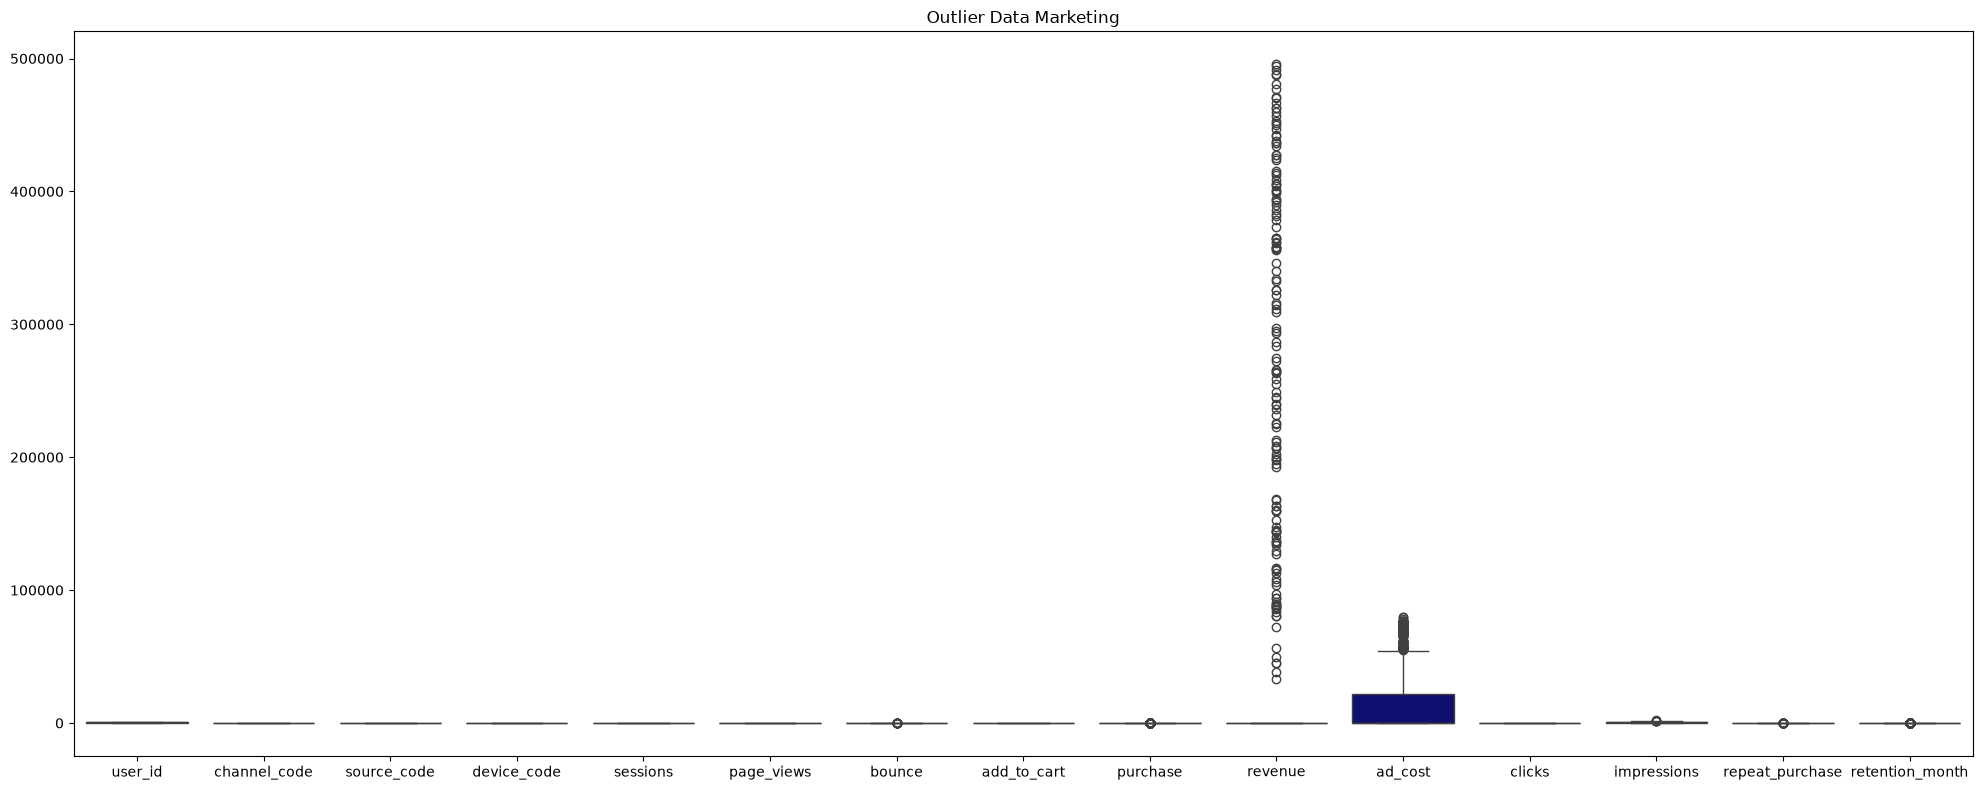

In [17]:
plt.figure(figsize=(20,8))
sns.boxplot(explore_numerik, color="navy")
plt.title("Outlier Data Marketing")
plt.tight_layout()
plt.show()

### Jumlah dan Persentase Outlier Dengan IQR

In [18]:
'''Membuat Variabel Baru Untuk Mengambil Nama Kolom Dengan Tipe Data Numerikal'''
kolom_outlier = df_copy.select_dtypes(include=["int64", "float64"]).columns

In [19]:
kolom_outlier

Index(['user_id', 'sessions', 'page_views', 'bounce', 'add_to_cart',
       'purchase', 'revenue', 'ad_cost', 'clicks', 'impressions',
       'repeat_purchase', 'retention_month', 'channel_code', 'source_code',
       'device_code'],
      dtype='str')

In [20]:
for i in kolom_outlier :
    Q1 = df_copy[i].quantile(0.25)
    Q3 = df_copy[i].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outlier = (df_copy[i] < lower) | (df_copy[i] > upper)
    jumlah_outlier = outlier.sum() # Mengetahui jumlah outlier pada kolom
    persentase_outlier = jumlah_outlier/len(outlier) * 100 # Mengetahui persentase outlier pada kolom
    print(f"Jumlah Outlier pada Kolom {i} : {jumlah_outlier}")
    print(f"Persentase Outlier pada Kolom {i} : {persentase_outlier:.2f}%\n")

Jumlah Outlier pada Kolom user_id : 0
Persentase Outlier pada Kolom user_id : 0.00%

Jumlah Outlier pada Kolom sessions : 0
Persentase Outlier pada Kolom sessions : 0.00%

Jumlah Outlier pada Kolom page_views : 0
Persentase Outlier pada Kolom page_views : 0.00%

Jumlah Outlier pada Kolom bounce : 26
Persentase Outlier pada Kolom bounce : 3.25%

Jumlah Outlier pada Kolom add_to_cart : 0
Persentase Outlier pada Kolom add_to_cart : 0.00%

Jumlah Outlier pada Kolom purchase : 150
Persentase Outlier pada Kolom purchase : 18.75%

Jumlah Outlier pada Kolom revenue : 150
Persentase Outlier pada Kolom revenue : 18.75%

Jumlah Outlier pada Kolom ad_cost : 89
Persentase Outlier pada Kolom ad_cost : 11.12%

Jumlah Outlier pada Kolom clicks : 0
Persentase Outlier pada Kolom clicks : 0.00%

Jumlah Outlier pada Kolom impressions : 7
Persentase Outlier pada Kolom impressions : 0.88%

Jumlah Outlier pada Kolom repeat_purchase : 48
Persentase Outlier pada Kolom repeat_purchase : 6.00%

Jumlah Outlier pa

### Cek Distribusi Data Dengan Uji Shapiro-Wilk

In [21]:
from scipy.stats import shapiro

In [22]:
for x in explore_numerik : 
    stat, p = shapiro(df_copy[x])
    print(f"p value Kolom {x} : {p:.3f}")
    if p >= 0.05 :
        print(f"Kolom {x} terdistribusi normal")
    else :
        print(f"Kolom {x} tidak terdistribusi normal\n")

p value Kolom user_id : 0.000
Kolom user_id tidak terdistribusi normal

p value Kolom channel_code : 0.000
Kolom channel_code tidak terdistribusi normal

p value Kolom source_code : 0.000
Kolom source_code tidak terdistribusi normal

p value Kolom device_code : 0.000
Kolom device_code tidak terdistribusi normal

p value Kolom sessions : 0.000
Kolom sessions tidak terdistribusi normal

p value Kolom page_views : 0.000
Kolom page_views tidak terdistribusi normal

p value Kolom bounce : 0.000
Kolom bounce tidak terdistribusi normal

p value Kolom add_to_cart : 0.000
Kolom add_to_cart tidak terdistribusi normal

p value Kolom purchase : 0.000
Kolom purchase tidak terdistribusi normal

p value Kolom revenue : 0.000
Kolom revenue tidak terdistribusi normal

p value Kolom ad_cost : 0.000
Kolom ad_cost tidak terdistribusi normal

p value Kolom clicks : 0.000
Kolom clicks tidak terdistribusi normal

p value Kolom impressions : 0.000
Kolom impressions tidak terdistribusi normal

p value Kolom re

### Insight Berdasarkan Hasil Eksplorasi

# Data Preparation

## Data Cleaning

### Menangani Tipe Data

In [23]:
df_copy["first_visit_date"] = pd.to_datetime(df_copy["first_visit_date"], format="%Y-%m-%d")

In [24]:
df_copy.info() # Memeriksa kembali tipe data

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           800 non-null    int64         
 1   first_visit_date  800 non-null    datetime64[us]
 2   channel           800 non-null    str           
 3   source            800 non-null    str           
 4   device            800 non-null    str           
 5   sessions          800 non-null    int64         
 6   page_views        800 non-null    int64         
 7   bounce            800 non-null    int64         
 8   add_to_cart       800 non-null    int64         
 9   purchase          800 non-null    int64         
 10  revenue           800 non-null    int64         
 11  ad_cost           800 non-null    int64         
 12  clicks            800 non-null    int64         
 13  impressions       800 non-null    int64         
 14  repeat_purchase   800 non-null    int

## Feature Engineering

In [25]:
'''Membuat Kolom Baru Berdasarkan Bulan Pelanggan Melakukan Kunjungan Pertama Kali'''
df_copy["Bulan"] = df_copy["first_visit_date"].dt.month    # Membuat Kolom Bulan berdasarkan bulan yang ada di kolom first_visit_date

In [26]:
df_copy["Bulan"].unique()

array([2, 1, 3], dtype=int32)

# EDA (Analisa Data)

## Analisis Univariat

### Distribusi Setiap Kolom Numerik

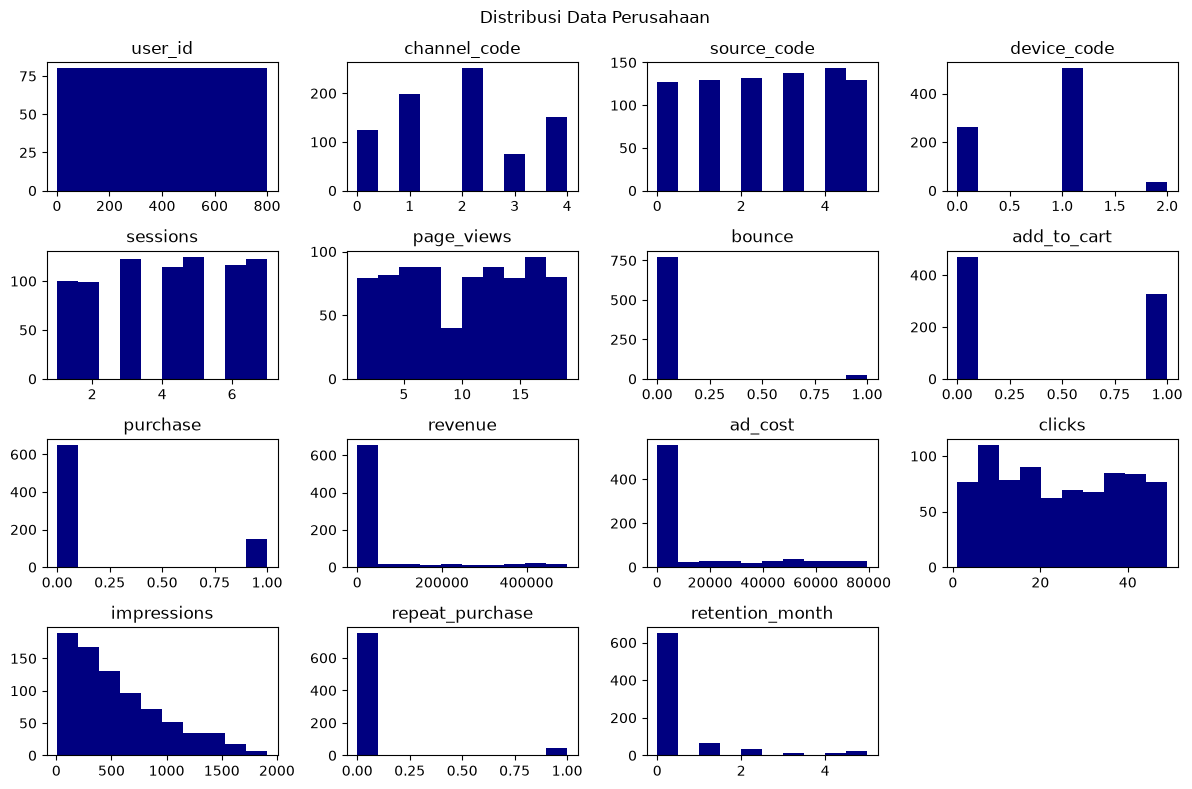

In [27]:
explore_numerik.hist(color='navy', figsize=(12,8), grid=False)
plt.suptitle("Distribusi Data Perusahaan")
plt.tight_layout()
plt.show()

### Analisis Biaya Paid Ads

In [28]:
iklan_bayar = df_copy[df_copy["channel"] == "Paid Ads"]
biaya_terbuang = iklan_bayar[iklan_bayar["purchase"] == 0]["ad_cost"].sum()
total_biaya = iklan_bayar["ad_cost"].sum()


print(f"Total biaya Paid Ads      : {total_biaya:,.0f}")
print(f"Biaya pada user tanpa beli : {biaya_terbuang:,.0f}")
print(f"Persentase biaya terbuang  : {biaya_terbuang / total_biaya * 100:.1f}%")

Total biaya Paid Ads      : 10,948,907
Biaya pada user tanpa beli : 8,530,392
Persentase biaya terbuang  : 77.9%


### Distribusi Channel

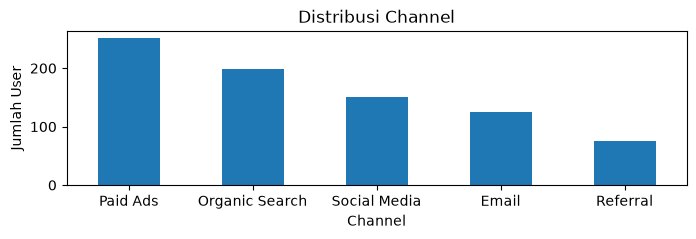

In [29]:
plt.figure(figsize=(8,2))
df_copy["channel"].value_counts().plot(kind="bar")
plt.title("Distribusi Channel")
plt.xlabel("Channel")
plt.ylabel("Jumlah User")
plt.xticks(rotation=0)
plt.show()

### Distribusi Source

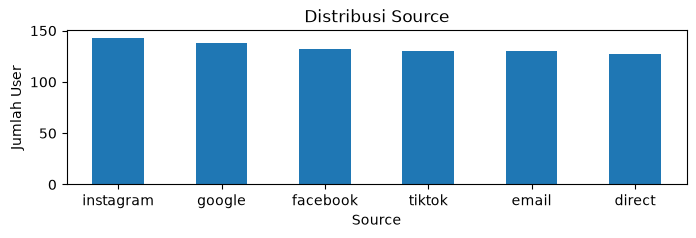

In [30]:
plt.figure(figsize=(8,2))
df_copy["source"].value_counts().plot(kind="bar")
plt.title("Distribusi Source")
plt.xlabel("Source")
plt.ylabel("Jumlah User")
plt.xticks(rotation=0)
plt.show()

### Distribusi Device

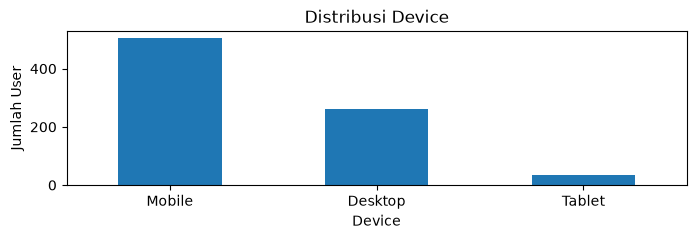

In [31]:
plt.figure(figsize=(8,2))
df_copy["device"].value_counts().plot(kind="bar")
plt.title("Distribusi Device")
plt.xlabel("Device")
plt.ylabel("Jumlah User")
plt.xticks(rotation=0)
plt.show()

### Distribusi Bulan

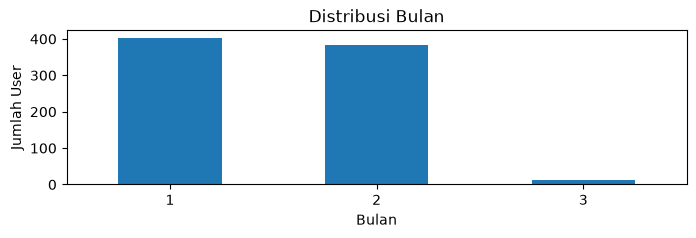

In [32]:
plt.figure(figsize=(8,2))
df_copy["Bulan"].value_counts().plot(kind="bar")
plt.title("Distribusi Bulan")
plt.xlabel("Bulan")
plt.ylabel("Jumlah User")
plt.xticks(rotation=0)
plt.show()

In [33]:
df_copy.groupby("Bulan").agg(
    jumlah_user = ("Bulan", "count")
)

,jumlah_user
Bulan,
1,403
2,384
3,13


In [34]:
df_copy[df_copy["Bulan"] == 3]

,user_id,first_visit_date,channel,source,device,sessions,page_views,bounce,add_to_cart,purchase,revenue,ad_cost,clicks,impressions,repeat_purchase,retention_month,channel_code,source_code,device_code,Bulan
37,38,2025-03-01,Organic Search,email,Mobile,3,8,0,1,0,0,0,37,444,0,0,1,1,1,3
77,78,2025-03-01,Referral,facebook,Desktop,6,12,0,0,0,0,0,9,198,0,0,3,2,0,3
85,86,2025-03-01,Organic Search,tiktok,Mobile,7,4,0,1,0,0,0,26,858,0,0,1,5,1,3
116,117,2025-03-01,Email,facebook,Mobile,2,10,0,1,1,249373,0,37,1184,0,1,0,2,1,3
163,164,2025-03-01,Paid Ads,instagram,Mobile,4,19,0,0,0,0,48509,22,726,0,0,2,4,1,3
215,216,2025-03-01,Organic Search,facebook,Desktop,1,12,0,0,0,0,0,38,1406,0,0,1,2,0,3
336,337,2025-03-01,Email,instagram,Mobile,7,10,0,1,0,0,0,32,736,0,0,0,4,1,3
394,395,2025-03-01,Email,tiktok,Mobile,4,6,0,1,1,136218,0,48,1728,0,4,0,5,1,3
451,452,2025-03-01,Paid Ads,google,Desktop,7,12,0,1,1,272472,76439,44,572,1,1,2,3,0,3
509,510,2025-03-01,Paid Ads,direct,Mobile,2,11,0,1,0,0,50713,33,726,0,0,2,0,1,3


## Analisis Bivariat

### Membandingkan Kolom Numerik dan Metriks Berdasarkan Channel

In [35]:
def bivariat(x) : 
    bi = df_copy.groupby(x).agg(
        Total_Penayangan = ("impressions", "sum"),
        Total_Klik = ("clicks", "sum"),
        Jumlah_Kunjungan = ("sessions", "sum"),
        Jumlah_Halaman_Terbaca = ("page_views", "sum"),
        Jumlah_Bounce = ("bounce", "sum"),
        Jumlah_Memasukkan_Keranjang = ("add_to_cart", "sum"),
        Jumlah_Pembeli_Pertama = ("purchase", "sum"),
        Total_Pembelian_Ulang = ("repeat_purchase", "sum"),
        Total_Revenue = ("revenue", "sum"),
        Total_Biaya = ("ad_cost", "sum")
    )
    bi["CTR"] = (bi["Total_Klik"]/bi["Total_Penayangan"]*100).round(2)
    bi["Conversion_Rate"] = (bi["Jumlah_Pembeli_Pertama"]/bi["Jumlah_Kunjungan"]*100).round(2)
    bi["ROAS"] = (bi["Total_Revenue"]/bi["Total_Biaya"]).round(2)
    bi["CAC"] = (bi["Total_Biaya"]/bi["Jumlah_Pembeli_Pertama"]).round(2)
    return bi.sort_values(by="ROAS", ascending=True)

In [36]:
bivariat("channel")

,Total_Penayangan,Total_Klik,Jumlah_Kunjungan,Jumlah_Halaman_Terbaca,Jumlah_Bounce,Jumlah_Memasukkan_Keranjang,Jumlah_Pembeli_Pertama,Total_Pembelian_Ulang,Total_Revenue,Total_Biaya,CTR,Conversion_Rate,ROAS,CAC
channel,,,,,,,,,,,,,,
Paid Ads,137844,5945,1032,2614,5,106,51,21,13177258,10948907,4.31,4.94,1.2,214684.45
Email,71912,2990,482,1209,3,47,20,5,4894673,0,4.16,4.15,inf,0.00
Organic Search,109047,5008,823,1969,10,78,31,8,7972474,0,4.59,3.77,inf,0.00
Referral,39040,1665,324,789,2,31,14,6,4446539,0,4.26,4.32,inf,0.00
Social Media,84857,3885,644,1462,6,67,34,8,10512961,0,4.58,5.28,inf,0.00


### Trend ROAS dari Paid Ads Setiap Bulan (Kecuali Bulan Maret)

In [37]:
roas_bulan = df_copy[(df_copy["channel"] == "Paid Ads") & (df_copy["Bulan"] != 3)].groupby("Bulan").agg(
    Total_Revenue = ("revenue", "sum"),
    Total_Biaya = ("ad_cost", "sum")
).reset_index()
roas_bulan["ROAS"] = (roas_bulan["Total_Revenue"] / roas_bulan["Total_Biaya"]).round(2)

roas_bulan

,Bulan,Total_Revenue,Total_Biaya,ROAS
0,1,7723633,5516531,1.40
1,2,5181153,5246169,0.99


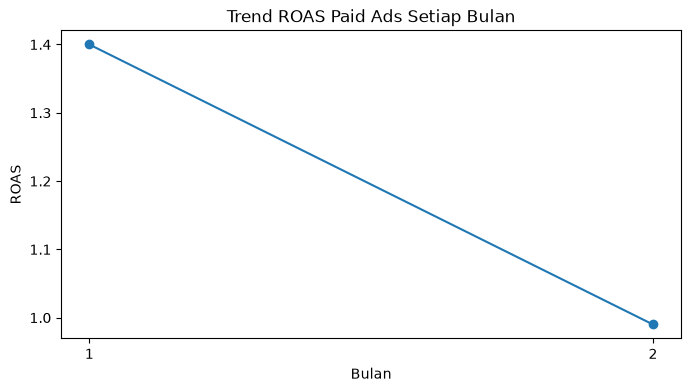

In [38]:
plt.figure(figsize=(8, 4))
plt.plot(roas_bulan["Bulan"], roas_bulan["ROAS"], marker="o")
plt.xticks(roas_bulan["Bulan"])
plt.title("Trend ROAS Paid Ads Setiap Bulan")
plt.xlabel("Bulan")
plt.ylabel("ROAS")
plt.show()

### Membandingkan Kolom Numerik dan Metriks Berdasarkan Device Dengan Filter Channel Paid Ads di Bulan Februari

In [39]:
def bivariat_device(x) : 
    bi = df_copy[(df_copy["channel"] == "Paid Ads") & (df_copy["Bulan"] == 2)].groupby(x).agg(
        Total_Penayangan = ("impressions", "sum"),
        Total_Klik = ("clicks", "sum"),
        Jumlah_Kunjungan = ("sessions", "sum"),
        Jumlah_Halaman_Terbaca = ("page_views", "sum"),
        Jumlah_Bounce = ("bounce", "sum"),
        Jumlah_Memasukkan_Keranjang = ("add_to_cart", "sum"),
        Jumlah_Pembeli_Pertama = ("purchase", "sum"),
        Total_Pembelian_Ulang = ("repeat_purchase", "sum"),
        Total_Revenue = ("revenue", "sum"),
        Total_Biaya = ("ad_cost", "sum")
    )
    bi["CTR"] = (bi["Total_Klik"]/bi["Total_Penayangan"]*100).round(2)
    bi["Conversion_Rate"] = (bi["Jumlah_Pembeli_Pertama"]/bi["Jumlah_Kunjungan"]*100).round(2)
    bi["ROAS"] = (bi["Total_Revenue"]/bi["Total_Biaya"]).round(2)
    bi["CAC"] = (bi["Total_Biaya"]/bi["Jumlah_Pembeli_Pertama"]).round(2)
    return bi.sort_values(by="ROAS", ascending=True)

In [40]:
bivariat_device("device")

,Total_Penayangan,Total_Klik,Jumlah_Kunjungan,Jumlah_Halaman_Terbaca,Jumlah_Bounce,Jumlah_Memasukkan_Keranjang,Jumlah_Pembeli_Pertama,Total_Pembelian_Ulang,Total_Revenue,Total_Biaya,CTR,Conversion_Rate,ROAS,CAC
device,,,,,,,,,,,,,,
Desktop,24279,1083,158,437,1,20,6,4,1581068,1720993,4.46,3.80,0.92,286832.17
Mobile,38931,1675,306,701,2,31,15,5,3259758,3314306,4.30,4.90,0.98,220953.73
Tablet,2294,108,7,35,0,1,1,0,340327,210870,4.71,14.29,1.61,210870.00


### Membandingkan Kolom Numerik dan Metriks Berdasarkan Source Dengan Filter Channel Paid Ads dan Device Desktop di Bulan Februari

In [41]:
def bivariat_source(x) : 
    bi = df_copy[(df_copy["channel"] == "Paid Ads") & (df_copy["Bulan"] == 2) & (df_copy["device"] == "Desktop")].groupby(x).agg(
        Total_Penayangan = ("impressions", "sum"),
        Total_Klik = ("clicks", "sum"),
        Jumlah_Kunjungan = ("sessions", "sum"),
        Jumlah_Halaman_Terbaca = ("page_views", "sum"),
        Jumlah_Bounce = ("bounce", "sum"),
        Jumlah_Memasukkan_Keranjang = ("add_to_cart", "sum"),
        Jumlah_Pembeli_Pertama = ("purchase", "sum"),
        Total_Pembelian_Ulang = ("repeat_purchase", "sum"),
        Total_Revenue = ("revenue", "sum"),
        Total_Biaya = ("ad_cost", "sum")
    )
    bi["CTR"] = (bi["Total_Klik"]/bi["Total_Penayangan"]*100).round(2)
    bi["Conversion_Rate"] = (bi["Jumlah_Pembeli_Pertama"]/bi["Jumlah_Kunjungan"]*100).round(2)
    bi["ROAS"] = (bi["Total_Revenue"]/bi["Total_Biaya"]).round(2)
    bi["CAC"] = (bi["Total_Biaya"]/bi["Jumlah_Pembeli_Pertama"]).round(2)
    return bi.sort_values(by="ROAS", ascending=True)

In [42]:
bivariat_source("source")

,Total_Penayangan,Total_Klik,Jumlah_Kunjungan,Jumlah_Halaman_Terbaca,Jumlah_Bounce,Jumlah_Memasukkan_Keranjang,Jumlah_Pembeli_Pertama,Total_Pembelian_Ulang,Total_Revenue,Total_Biaya,CTR,Conversion_Rate,ROAS,CAC
source,,,,,,,,,,,,,,
email,6644,304,25,134,0,4,0,0,0,305805,4.58,0.00,0.00,inf
tiktok,6096,205,35,83,0,3,0,0,0,339047,3.36,0.00,0.00,inf
facebook,4360,164,29,64,0,3,1,1,80539,378933,3.76,3.45,0.21,378933.0
direct,3602,204,31,62,1,5,2,1,422678,269692,5.66,6.45,1.57,134846.0
instagram,1450,103,22,53,0,2,1,1,311787,149036,7.10,4.55,2.09,149036.0
google,2127,103,16,41,0,3,2,1,766064,278480,4.84,12.50,2.75,139240.0


### Analisis Bivariat Kolom Numerik

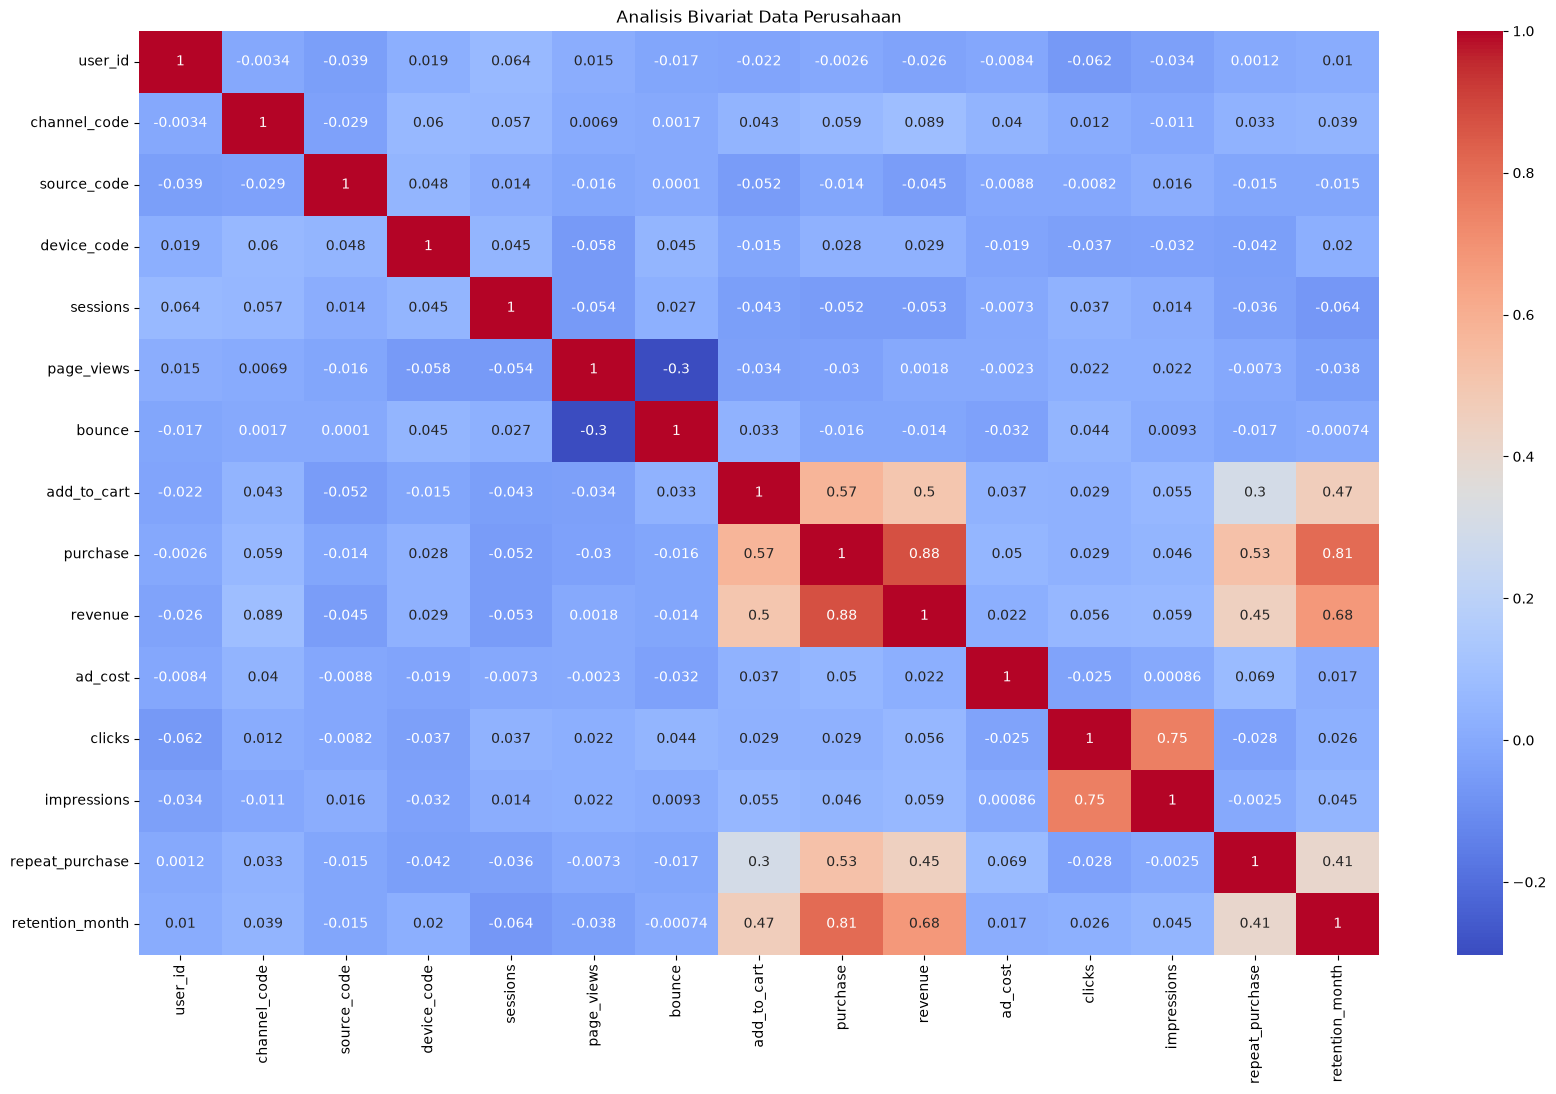

In [43]:
df_corr = explore_numerik.corr()
plt.figure(figsize=(20, 12))
sns.heatmap(
    df_corr,
    annot=True,
    cmap="coolwarm"
)
plt.title("Analisis Bivariat Data Perusahaan")
plt.show()

## Analisis Multivariat

### Analisis Device dan Source Yang Menggunakan Channel Paid Ads di Bulan Februari dengan Metriks Total Revenue, Total Biaya, Jumlah Kunjungan, Total Pembeli, dan ROAS Menggunakan Tabel

In [44]:
def multivariat():
    multi = df_copy[(df_copy["channel"] == "Paid Ads") & (df_copy["Bulan"] == 2)].groupby(["device", "source"]).agg(
        Total_Revenue = ("revenue", "sum"),
        Total_Biaya = ("ad_cost", "sum"),
        Jumlah_Kunjungan = ("sessions", "sum"),
        Total_Pembeli = ("purchase", "sum")
    )
    multi["ROAS"] = (multi["Total_Revenue"] / multi["Total_Biaya"]).round(2)   
    return multi.sort_values(by="ROAS", ascending=True)

In [45]:
multivariat()

Total_Revenue  Total_Biaya  Jumlah_Kunjungan  \
device  source                                                    
Desktop email                  0       305805                25   
        tiktok                 0       339047                35   
Tablet  instagram              0       143178                 5   
Mobile  instagram          45228       519808                40   
Desktop facebook           80539       378933                29   
Mobile  tiktok            707639       824942                83   
        direct            532565       604805                56   
        facebook          533046       472711                53   
Desktop direct            422678       269692                31   
Mobile  google            604639       374576                30   
        email             836641       517464                44   
Desktop instagram         311787       149036                22   
        google            766064       278480                16   
Tablet  facebook          340327        67692                 2   

                   Total_Pembeli  ROAS  
device  source                          
Desktop email                  0  0.00  
        tiktok                 0  0.00  
Tablet  instagram              0  0.00  
Mobile  instagram              1  0.09  
Desktop facebook               1  0.21  
Mobile  tiktok                 4  0.86  
        direct                 2  0.88  
        facebook               2  1.13  
Desktop direct                 2  1.57  
Mobile  google                 2  1.61  
        email                  4  1.62  
Desktop instagram              1  2.09  
        google                 2  2.75  
Tablet  facebook               1  5.03

### Analisis Device dan Source Yang Menggunakan Channel Paid Ads di Bulan Februari dengan Metriks Total Revenue, Total Biaya, Jumlah Kunjungan, Total Pembeli, dan ROAS Menggunakan Heatmap

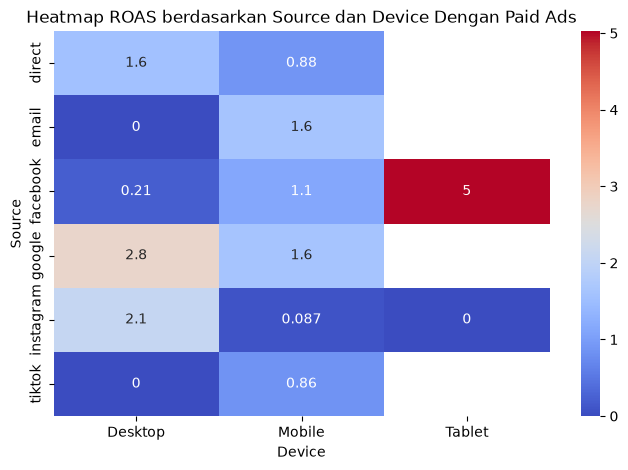

In [46]:
revenue_pivot = df_copy[(df_copy["channel"] == "Paid Ads") & (df_copy["Bulan"] == 2)].pivot_table(index="source", columns="device", values="revenue", aggfunc="sum")
cost_pivot = df_copy[(df_copy["channel"] == "Paid Ads") & (df_copy["Bulan"] == 2)].pivot_table(index="source", columns="device", values="ad_cost", aggfunc="sum")
roas_pivot = revenue_pivot / cost_pivot


plt.figure(figsize=(8, 5))
sns.heatmap(
    roas_pivot, 
    annot=True,
    cmap="coolwarm"
)
plt.title("Heatmap ROAS berdasarkan Source dan Device Dengan Paid Ads")
plt.xlabel("Device")
plt.ylabel("Source")
plt.xticks(rotation=0)
plt.show()

# Export Data Bersih

In [47]:
df_clean = df_copy[["user_id", "first_visit_date", "Bulan", "channel", "source", "device", "sessions", "page_views", "bounce", "add_to_cart", "purchase", "revenue", "ad_cost", "clicks", "impressions", "repeat_purchase", "retention_month"]]

In [48]:
df_clean.to_csv("clean_dataset_marketing_growth_analytics.csv", index=False)